# Comparação de modelos — desenvolvimento

Comparação inicial e otimizada já concluídas. Referência majoritária, regressão logística, floresta e boosting utilizam as mesmas quatro features e validação temporal. O notebook apresenta evidências registradas, sem retreinar ou consultar o teste. A avaliação final está no notebook 04.

In [1]:
from pathlib import Path
import json, sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'submission/manifest.json').is_file() and (p/'src/fire_risk').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Abra o notebook dentro da pasta extraída ou do clone completo do projeto.')
sys.path.insert(0, str(ROOT/'src'))
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from fire_risk.submission import verify_submission, training_correlations
panel, manifest = verify_submission(ROOT)
def evidence(name):
    return json.loads((ROOT/'submission/evidence'/name).read_text(encoding='utf-8'))
print('Base consolidada íntegra:', len(panel), 'municípios/dia; partições:', manifest['splits'])
print('Modelo congelado:', manifest['model_id'])


Base consolidada íntegra: 1329 municípios/dia; partições: {'train': 764, 'test': 310, 'validation': 183, 'gap': 72}
Modelo congelado: 852606b93da31ade


## Separação e prevenção de vazamento

Treino até 25/01, validação de 27/01 a 02/02, teste de 04/02 a 12/02. Os dias 26/01 e 03/02 são intervalos. A escala e pesos são aprendidos somente no ajuste. Optuna utiliza três folds cronológicos internos ao treino, 20 tentativas por família. A seleção usa F1 macro e desempate por recall alto e nome, nunca o teste.

                     f1_macro  accuracy precision_macro recall_macro recall_alto auc_ovr_macro
referencia           0.290123  0.770492        0.256831     0.333333         0.0           0.5
logistica            0.442933  0.650273        0.445419     0.508644     0.28125      0.708814
floresta             0.412147  0.693989        0.415342     0.411732      0.3125       0.67621
boosting             0.366991   0.68306        0.375361     0.359929        0.25      0.642811
otimizada_logistica  0.452758  0.666667        0.453517     0.515736     0.28125       0.70612
otimizada_floresta    0.37497  0.622951        0.389238     0.372946     0.28125      0.673124
otimizada_boosting   0.402516  0.622951        0.425309     0.411968      0.3125       0.67957
Folds:  train_end validation_start validation_end  train_rows  validation_rows
2025-01-12       2025-01-14     2025-01-17         355               86
2025-01-16       2025-01-18     2025-01-21         436              120
2025-01-20       

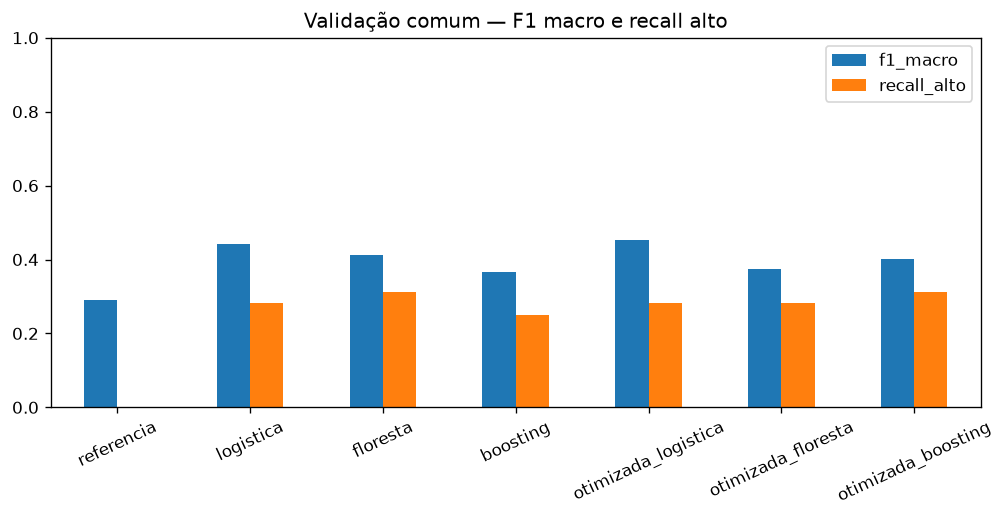

In [2]:
optimization=evidence('optimization.json')
metrics=pd.DataFrame(optimization['validation']).T
print(metrics[['f1_macro','accuracy','precision_macro','recall_macro','recall_alto','auc_ovr_macro']].to_string())
print('Folds:',pd.DataFrame(optimization['folds']).to_string(index=False))
print('Parâmetros:',{name:entry['best_params'] for name,entry in optimization['studies'].items()})
metrics[['f1_macro','recall_alto']].astype(float).plot.bar(figsize=(10,4),rot=25,ylim=(0,1)); plt.title('Validação comum — F1 macro e recall alto')


## Interpretação

A logística otimizada foi selecionada por F1 macro de validação 0,4528, frente a 0,2901 da referência. O recall alto de validação permanece limitado: otimizar não garante ganho em todas as classes. A avaliação final foi congelada antes de observar o teste e é apresentada no notebook seguinte; não há seleção adicional baseada na EDA complementar.